# Bank Marketing — Exploratory Data Analysis (EDA)

## О проекте

**Цель проекта:** исследовать факторы, связанные с откликом клиентов на банковские маркетинговые предложения, и сравнить качество логистической регрессии и SVM для прогнозирования открытия срочного депозита.

В работе используются данные телефонных маркетинговых кампаний португальского банка.

**Целевая переменная:** `y` — результат маркетинговой кампании:
- `0` — клиент не открыл срочный депозит;
- `1` — клиент открыл срочный депозит.

**Рассматриваемые модели:**
- Logistic Regression;
- Linear SVM;
- RBF SVM.

## Цель текущего этапа

Провести исследовательский анализ данных (EDA), изучить распределения признаков, выявить статистические зависимости и определить особенности данных, которые необходимо учесть при построении моделей.

**Основные задачи:**
1. Изучить структуру и качество данных.
2. Исследовать распределение целевой переменной.
3. Проанализировать числовые и категориальные признаки.
4. Изучить взаимосвязи между признаками и их связь с целевой переменной.
5. Сформулировать выводы и рекомендации для предобработки данных.

**Датасет:** [Bank Marketing — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing)

## 1. Загрузка данных

Импорт библиотек и загрузка датасета `banking.csv`.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
project_root = Path.cwd().resolve()

if project_root.name == 'notebooks':
    project_root = project_root.parent

# Загружаем полный датасет
df_all = pd.read_csv(
    project_root / 'data' / 'raw' / 'banking.csv'
)

# Выделяем признаки и целевую переменную
X = df_all.drop(columns=['y', 'duration'])
y = df_all['y'].copy()

# Воспроизводим разделение из 02_preprocessing.ipynb
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Для EDA используем только обучающие наблюдения
df = df_all.loc[X_train.index].copy()

print('Исходный датасет:', df_all.shape)
print('Train:', df.shape)
print('Test:', X_test.shape)

df.head()


Исходный датасет: (41188, 21)
Train: (32950, 21)
Test: (8238, 19)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
27549,30,management,married,university.degree,no,no,no,cellular,nov,wed,...,5,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,0
27965,38,admin.,single,university.degree,unknown,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.858,5191.0,0
36497,51,blue-collar,married,high.school,no,yes,no,cellular,may,wed,...,1,999,1,failure,-1.8,92.893,-46.2,1.281,5099.1,1
315,37,technician,single,professional.course,no,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
38191,43,management,married,university.degree,no,no,no,cellular,nov,tue,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,0


## 2. Первичное исследование данных

Изучение структуры датасета.

In [3]:
# Первые строки
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
27549,30,management,married,university.degree,no,no,no,cellular,nov,wed,...,5,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,0
27965,38,admin.,single,university.degree,unknown,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.858,5191.0,0
36497,51,blue-collar,married,high.school,no,yes,no,cellular,may,wed,...,1,999,1,failure,-1.8,92.893,-46.2,1.281,5099.1,1
315,37,technician,single,professional.course,no,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
38191,43,management,married,university.degree,no,no,no,cellular,nov,tue,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,0


In [4]:
# Размер датасета
df.shape

(32950, 21)

In [5]:
# Информация о признаках
df.info()

<class 'pandas.DataFrame'>
Index: 32950 entries, 27549 to 11701
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             32950 non-null  int64  
 1   job             32950 non-null  str    
 2   marital         32950 non-null  str    
 3   education       32950 non-null  str    
 4   default         32950 non-null  str    
 5   housing         32950 non-null  str    
 6   loan            32950 non-null  str    
 7   contact         32950 non-null  str    
 8   month           32950 non-null  str    
 9   day_of_week     32950 non-null  str    
 10  duration        32950 non-null  int64  
 11  campaign        32950 non-null  int64  
 12  pdays           32950 non-null  int64  
 13  previous        32950 non-null  int64  
 14  poutcome        32950 non-null  str    
 15  emp_var_rate    32950 non-null  float64
 16  cons_price_idx  32950 non-null  float64
 17  cons_conf_idx   32950 non-null  float64
 18

In [6]:
# Описательная статистика
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32950.0,40.057845,10.425273,17.000,32.000,38.000,47.000,98.000
duration,32950.0,258.029135,257.158916,0.000,102.000,179.000,320.000,4918.000
campaign,32950.0,2.555205,2.740937,1.000,1.000,2.000,3.000,56.000
pdays,32950.0,962.204734,187.573778,0.000,999.000,999.000,999.000,999.000
previous,32950.0,0.173687,0.496153,0.000,0.000,0.000,0.000,7.000
emp_var_rate,32950.0,0.083405,1.571814,-3.400,-1.800,1.100,1.400,1.400
cons_price_idx,32950.0,93.575810,0.578764,92.201,93.075,93.749,93.994,94.767
cons_conf_idx,32950.0,-40.491259,4.629662,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,32950.0,3.622089,1.735217,0.634,1.344,4.857,4.961,5.045
nr_employed,32950.0,5167.045390,72.389630,4963.600,5099.100,5191.000,5228.100,5228.100


In [7]:
# Статистика категориальных признаков
df.describe(include='str').T

,count,unique,top,freq
job,32950,12,admin.,8298
marital,32950,4,married,20013
education,32950,8,university.degree,9725
default,32950,3,no,26080
housing,32950,3,yes,17275
loan,32950,3,no,27189
contact,32950,2,cellular,20901
month,32950,10,may,11004
day_of_week,32950,5,thu,6919
poutcome,32950,3,nonexistent,28442


### Общая характеристика данных

Исходный датасет содержит 41 188 наблюдений и 21 столбец. Перед проведением EDA данные разделены на обучающую (80%) и тестовую (20%) выборки. Дальнейший анализ выполняется только на обучающей выборке из 32 950 наблюдений.
- 10 числовых признаков;
- 10 категориальных признаков;
- 1 целевую переменную `y`.

Числовые признаки включают характеристики клиентов, историю
маркетинговых контактов и экономические показатели.
Категориальные признаки описывают социально-демографические
характеристики клиентов и условия проведения кампаний.

## 3. Проверка качества данных

Проверка наличия пропущенных значений, дубликатов и неизвестных категорий (`unknown`).

In [8]:
# Проверка на пропущенные значения
df.isna().sum().sum()

np.int64(0)

In [9]:
# Проверка на дубликаты
print('Полные дубликаты:', df.duplicated().sum())

Полные дубликаты: 7


In [10]:
df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
8178,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,0
34333,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,0
39423,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,0
12041,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,0
37214,39,admin.,married,university.degree,no,no,no,cellular,nov,tue,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,0
41181,39,admin.,married,university.degree,no,no,no,cellular,nov,tue,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,0
4601,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,0
25634,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,0
17954,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,0
17977,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,0


In [11]:
# Признаки, содержащие 'unknown'
unknown_counts = (df == 'unknown').sum()

unknown_counts[unknown_counts > 0]

job           257
marital        69
education    1390
default      6868
housing       804
loan          804
dtype: int64

In [12]:
# Доля 'unknown' в процентах
unknown_share = (df == 'unknown').mean() * 100

unknown_share[unknown_share > 0].round(2)

job           0.78
marital       0.21
education     4.22
default      20.84
housing       2.44
loan          2.44
dtype: float64

In [13]:
(df['housing'] == 'unknown').equals(
    df['loan'] == 'unknown'
)

True

### Выводы

- В обучающей выборке пропущенных значений (NaN) не обнаружено.
- Обнаружено 7 полных дубликатов (0,02%). Пока оставим их, поскольку нельзя однозначно определить причину повторений.
- В шести категориальных признаках встречается `unknown`. Наибольшая доля таких значений в `default` — 20,84%.
- В признаках `housing` и `loan` значения `unknown` встречаются у одних и тех же наблюдений (2,44%). При этом сами признаки содержат разную информацию.

## 4. Анализ целевой переменной

Исследуем распределение целевой переменной `y`, отражающей результат маркетинговой кампании.

Определим количество и долю положительных и отрицательных откликов, оценим баланс классов и его возможное влияние на выбор метрик классификации.

In [14]:
# Распределение целевой переменной
df['y'].value_counts()

y
0    29238
1     3712
Name: count, dtype: int64

In [15]:
# Доля целевой переменной
(df['y'].value_counts(normalize=True) * 100).round(2)

y
0    88.73
1    11.27
Name: proportion, dtype: float64

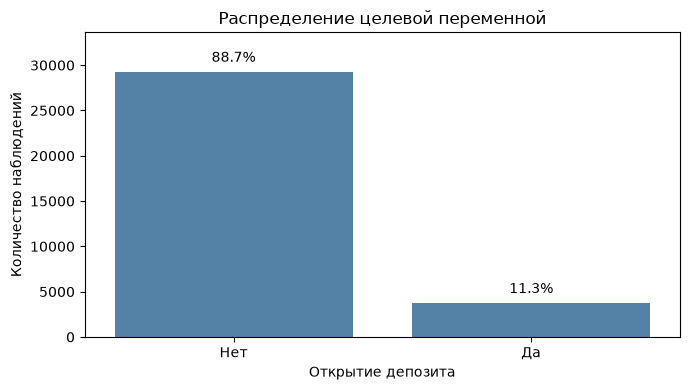

In [16]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x='y',
    order=[0, 1],
    color='steelblue'
)

plt.title('Распределение целевой переменной')
plt.xlabel('Открытие депозита')
plt.ylabel('Количество наблюдений')

ax.set_xticks([0, 1])
ax.set_xticklabels(['Нет', 'Да'])

total = len(df)

for bar in ax.patches:
    count = bar.get_height()
    percentage = count / total * 100

    ax.annotate(
        f'{percentage:.1f}%',
        (bar.get_x() + bar.get_width() / 2, count),
        ha='center',
        va='bottom',
        xytext=(0, 5),
        textcoords='offset points'
    )
ax.set_ylim(0, df['y'].value_counts().max() * 1.15)
plt.tight_layout()
plt.show()

### Выводы

- В данных наблюдается выраженный дисбаланс классов: 88,73% клиентов не открыли депозит, 11,27% — открыли.
- Из-за дисбаланса Accuracy недостаточно для оценки качества классификации. Основной метрикой сравнения моделей будет Average Precision (AP). Дополнительно рассмотрим ROC-AUC, Precision, Recall и F1-score.
- При разделении данных была использована стратификация для сохранения соотношения классов в Train и Test.

## 5. Анализ числовых признаков

Изучим распределения числовых признаков, возможные выбросы и их связь с целевой переменной. Также проверим корреляции между признаками, чтобы выявить особенности, которые могут повлиять на обучение моделей.

### 5.1. Распределения числовых признаков

Рассмотрим основные статистические характеристики числовых признаков и построим гистограммы. Дополнительно оценим асимметрию распределений с помощью коэффициента `skew`.

In [17]:
num_cols = df.select_dtypes(include='number').columns.drop('y')

num_cols.tolist()

['age',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'emp_var_rate',
 'cons_price_idx',
 'cons_conf_idx',
 'euribor3m',
 'nr_employed']

In [18]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,32950.0,40.057845,10.425273,17.000,32.000,38.000,47.000,98.000
duration,32950.0,258.029135,257.158916,0.000,102.000,179.000,320.000,4918.000
campaign,32950.0,2.555205,2.740937,1.000,1.000,2.000,3.000,56.000
pdays,32950.0,962.204734,187.573778,0.000,999.000,999.000,999.000,999.000
previous,32950.0,0.173687,0.496153,0.000,0.000,0.000,0.000,7.000
emp_var_rate,32950.0,0.083405,1.571814,-3.400,-1.800,1.100,1.400,1.400
cons_price_idx,32950.0,93.575810,0.578764,92.201,93.075,93.749,93.994,94.767
cons_conf_idx,32950.0,-40.491259,4.629662,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,32950.0,3.622089,1.735217,0.634,1.344,4.857,4.961,5.045
nr_employed,32950.0,5167.045390,72.389630,4963.600,5099.100,5191.000,5228.100,5228.100


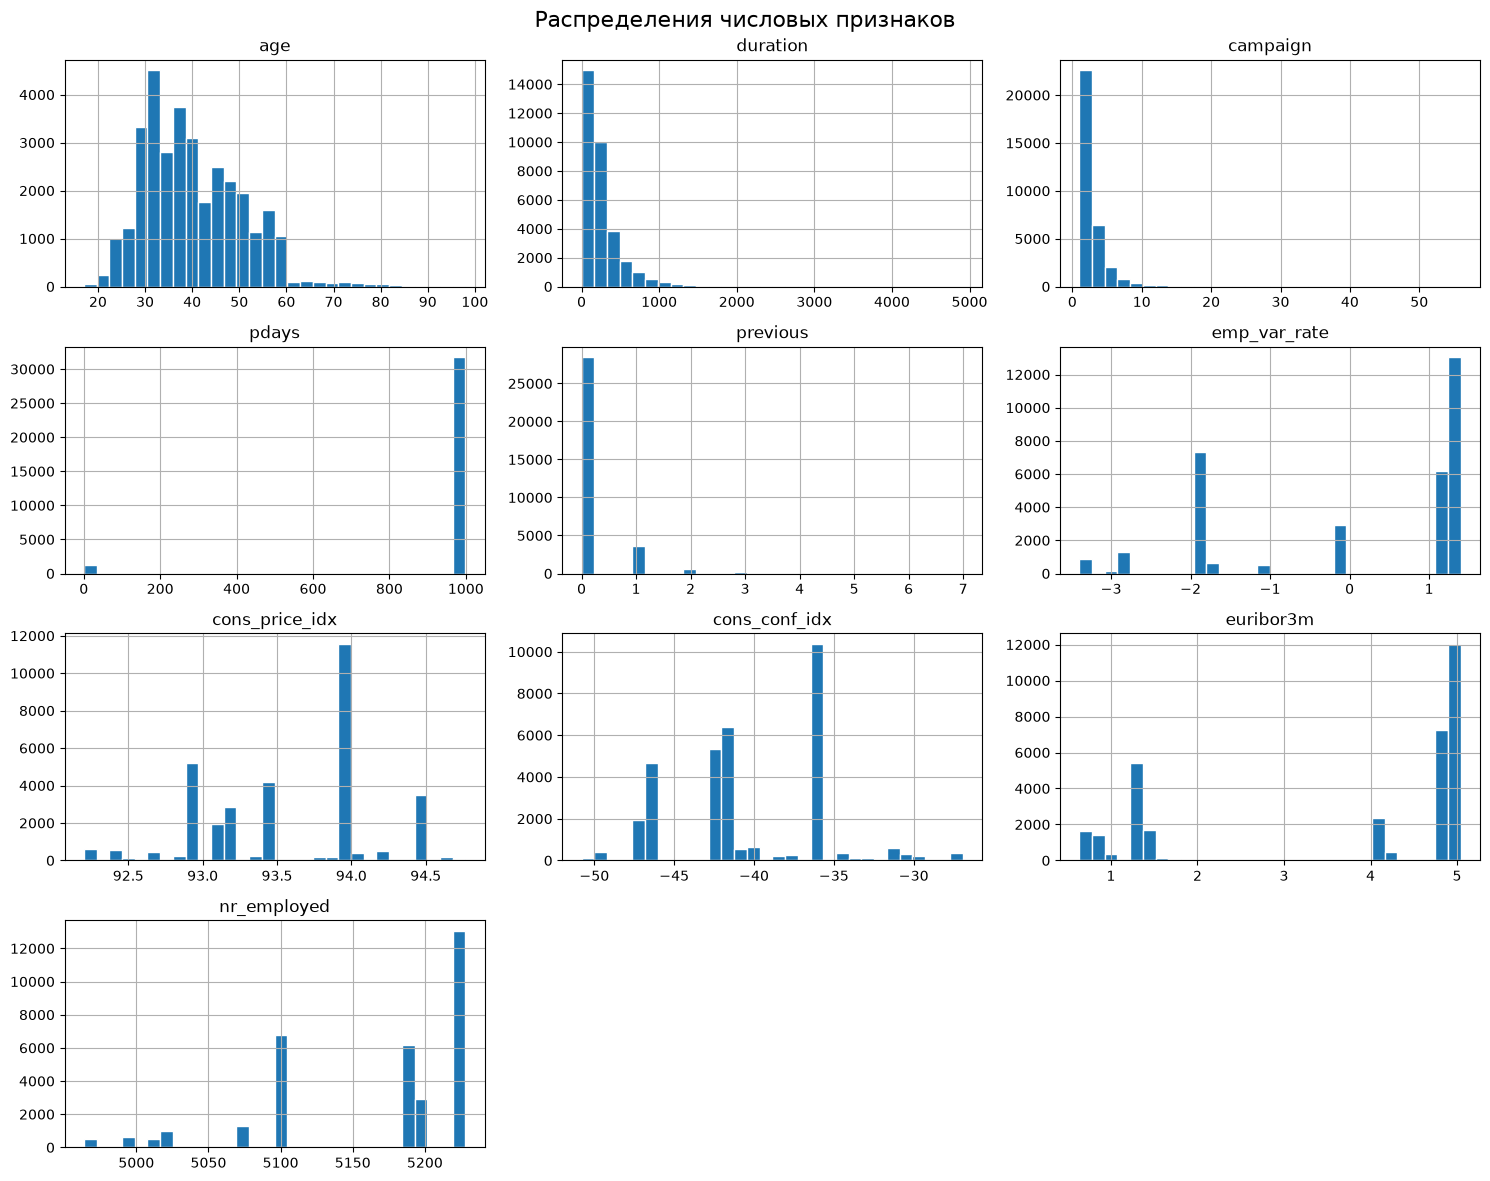

In [19]:
df[num_cols].hist(
    bins=30,
    figsize=(15, 12),
    edgecolor='white'
)

plt.suptitle('Распределения числовых признаков', fontsize=16)
plt.tight_layout()
plt.show()

In [20]:
df[num_cols].skew().sort_values(ascending=False)

campaign          4.753123
previous          3.789723
duration          3.169905
age               0.787530
cons_conf_idx     0.302929
cons_price_idx   -0.232168
euribor3m        -0.710699
emp_var_rate     -0.726819
nr_employed      -1.045448
pdays            -4.901826
dtype: float64

### 5.2. Анализ выбросов

С помощью диаграмм размаха проверим наличие потенциальных выбросов в числовых признаках.

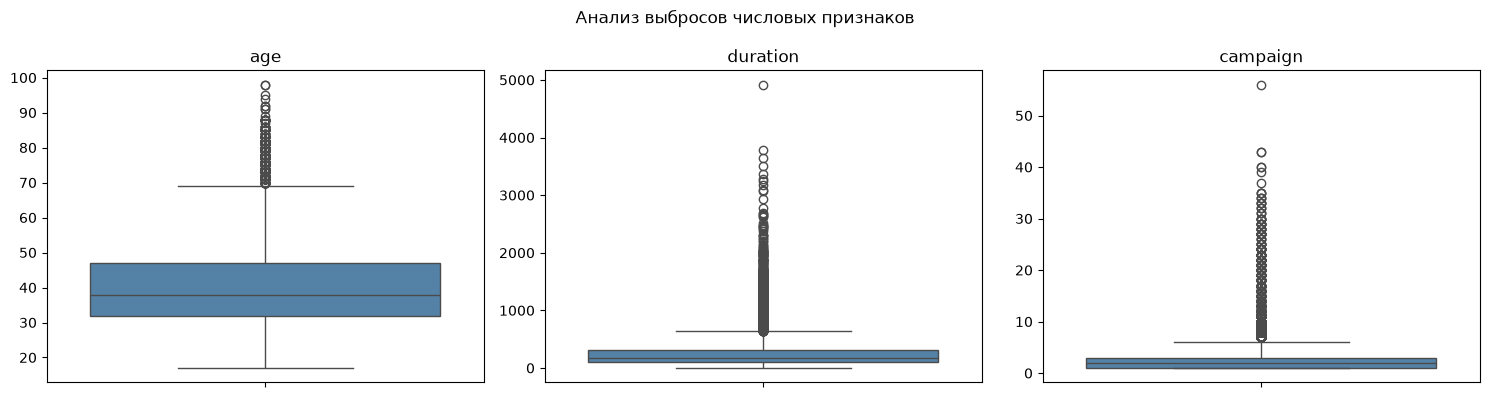

In [21]:
cols = ['age', 'duration', 'campaign']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    sns.boxplot(
        data=df,
        y=col,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(col)
    ax.set_ylabel('')

plt.suptitle('Анализ выбросов числовых признаков')

plt.tight_layout()
plt.show()

In [22]:
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    print(
        f'{col}: {outliers.sum()} '
        f'({outliers.mean() * 100:.2f}%)'
    )

age: 376 (1.14%)
duration: 2353 (7.14%)
campaign: 1889 (5.73%)


### 5.3. Особенности отдельных признаков

Отдельно рассмотрим признаки `pdays` и `previous`, связанные с историей предыдущих маркетинговых контактов.

In [23]:
df['pdays'].value_counts().head(10)

pdays
999    31729
3        350
6        342
4         96
7         56
9         49
2         45
10        45
12        41
5         34
Name: count, dtype: int64

In [24]:
(df['pdays'] == 999).mean() * 100

np.float64(96.29438543247343)

In [25]:
df['previous'].value_counts().sort_index()

previous
0    28442
1     3646
2      607
3      177
4       62
5       13
6        2
7        1
Name: count, dtype: int64

In [26]:
(df['previous'] == 0).mean() * 100

np.float64(86.31866464339909)

In [27]:
pd.crosstab(
    df['previous'] == 0,
    df['pdays'] == 999
)

pdays,False,True
previous,,
False,1221,3287
True,0,28442


In [28]:
pd.crosstab(
    df['previous'] == 0,
    df['pdays'] == 999,
    normalize='index'
).round(3)

pdays,False,True
previous,,
False,0.271,0.729
True,0.000,1.000


### 5.4. Сравнение признаков по целевой переменной

Сравним числовые признаки для клиентов с положительным и отрицательным откликом. Рассмотрим различия в средних значениях, медианах и распределениях, чтобы выявить признаки, потенциально полезные для классификации.

In [29]:
df.groupby('y')[num_cols].median().T

y,0,1
age,38.000,37.000
duration,163.500,452.000
campaign,2.000,2.000
pdays,999.000,999.000
previous,0.000,0.000
emp_var_rate,1.100,-1.800
cons_price_idx,93.918,93.200
cons_conf_idx,-41.800,-40.400
euribor3m,4.857,1.266
nr_employed,5195.800,5099.100


In [30]:
df.groupby('y')[num_cols].mean().T

y,0,1
age,39.963096,40.804149
duration,221.109686,548.829472
campaign,2.618134,2.059537
pdays,984.195670,788.990571
previous,0.132430,0.498653
emp_var_rate,0.251553,-1.241029
cons_price_idx,93.603893,93.354608
cons_conf_idx,-40.589425,-39.718050
euribor3m,3.812716,2.120598
nr_employed,5176.214936,5094.820393


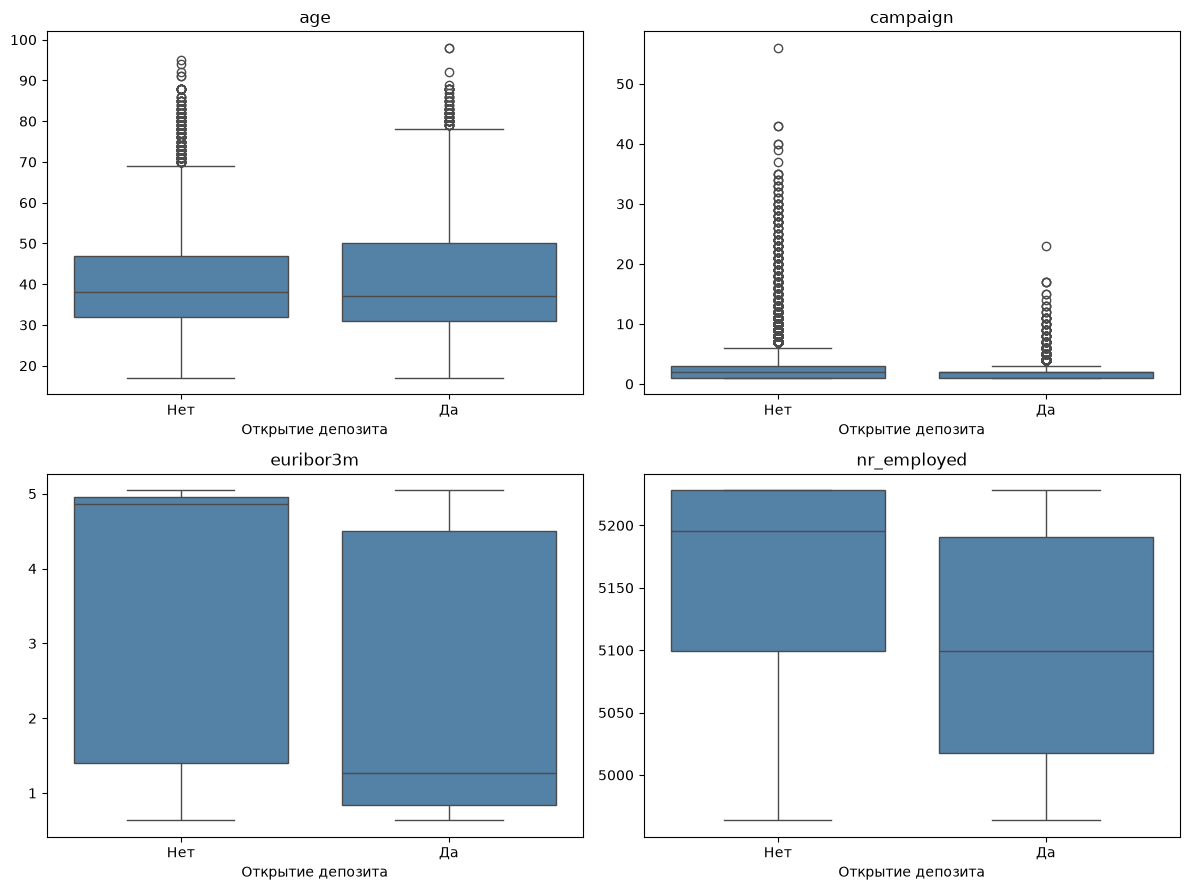

In [31]:
compare_cols = [
    'age',
    'campaign',
    'euribor3m',
    'nr_employed'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flat, compare_cols):
    sns.boxplot(
        data=df,
        x='y',
        y=col,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(col)
    ax.set_xlabel('Открытие депозита')
    ax.set_ylabel('')

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Нет', 'Да'])

plt.tight_layout()
plt.show()

In [32]:
age_bins = [0, 25, 35, 45, 55, 65, 100]

age_labels = [
    '<25',
    '25–34',
    '35–44',
    '45–54',
    '55–64',
    '65+'
]

age_groups = pd.cut(
    df['age'],
    bins=age_bins,
    labels=age_labels,
    right=False
)

In [33]:
age_response = (
    df.groupby(age_groups, observed=True)['y']
    .agg(['mean', 'count'])
)

age_response['response_rate'] = age_response['mean'] * 100

age_response[['count', 'response_rate']].round(2)

,count,response_rate
age,,
<25,842,25.18
25–34,10926,12.23
35–44,10795,8.74
45–54,6997,8.32
55–64,2853,13.53
65+,537,46.93


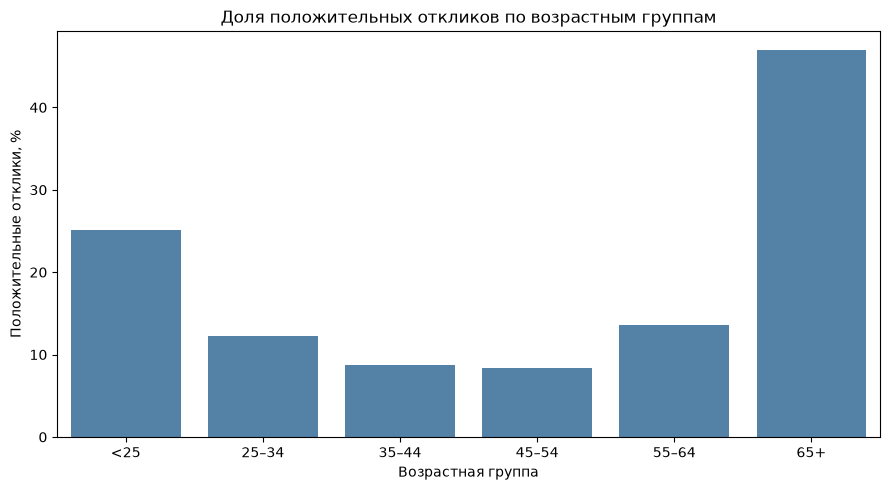

In [34]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_response.index.astype(str),
    y=age_response['response_rate'],
    color='steelblue'
)

plt.title('Доля положительных откликов по возрастным группам')
plt.xlabel('Возрастная группа')
plt.ylabel('Положительные отклики, %')

plt.tight_layout()
plt.show()

In [35]:
campaign_response = (
    df.groupby('campaign')['y']
    .agg(['mean', 'count'])
)

campaign_response['response_rate'] = (
    campaign_response['mean'] * 100
)

campaign_response[['count', 'response_rate']].round(2).head(10)

,count,response_rate
campaign,,
1,14180,12.97
2,8402,11.41
3,4277,10.64
4,2129,9.63
5,1296,8.02
6,777,8.11
7,502,6.37
8,324,4.32
9,217,5.53


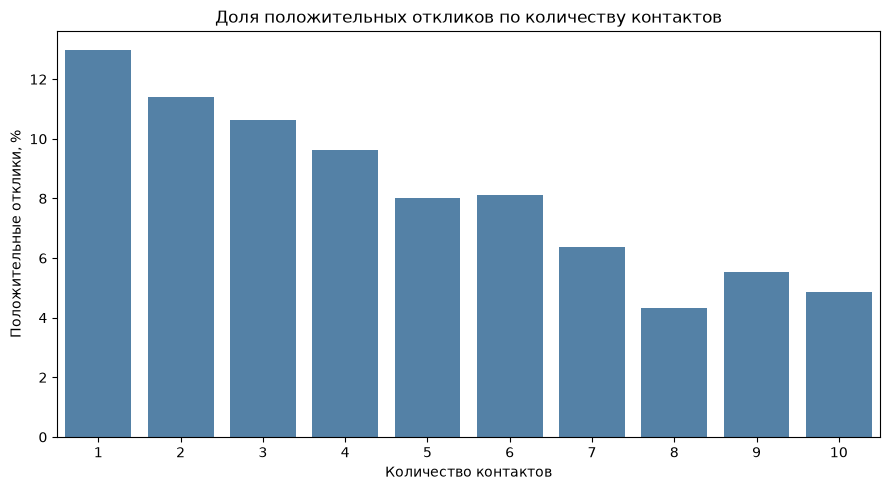

In [36]:
campaign_plot = campaign_response.loc[
    campaign_response.index <= 10
]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=campaign_plot.index,
    y=campaign_plot['response_rate'],
    color='steelblue'
)

plt.title('Доля положительных откликов по количеству контактов')
plt.xlabel('Количество контактов')
plt.ylabel('Положительные отклики, %')

plt.tight_layout()
plt.show()

### 5.5. Корреляционный анализ

Рассчитаем коэффициенты корреляции Пирсона между числовыми признаками и построим тепловую карту.

Выделим наиболее сильные линейные связи и оценим возможную мультиколлинеарность, которую необходимо учитывать при построении моделей.

In [37]:
# Изучим корелляции вещественных признаков

corr_matrix = df[num_cols].corr()

corr_matrix

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
age,1.000000,-0.002027,0.007352,-0.034497,0.025371,0.002879,0.005423,0.129178,0.013511,-0.016437
duration,-0.002027,1.000000,-0.073899,-0.048078,0.022099,-0.028659,0.009695,-0.010603,-0.033425,-0.046366
campaign,0.007352,-0.073899,1.000000,0.051714,-0.079460,0.148650,0.123814,-0.012659,0.132993,0.141618
pdays,-0.034497,-0.048078,0.051714,1.000000,-0.587765,0.275190,0.082366,-0.101747,0.299896,0.375843
previous,0.025371,0.022099,-0.079460,-0.587765,1.000000,-0.422307,-0.204670,-0.043279,-0.455685,-0.503136
emp_var_rate,0.002879,-0.028659,0.148650,0.275190,-0.422307,1.000000,0.774654,0.192692,0.972232,0.907147
cons_price_idx,0.005423,0.009695,0.123814,0.082366,-0.204670,0.774654,1.000000,0.056662,0.687515,0.521542
cons_conf_idx,0.129178,-0.010603,-0.012659,-0.101747,-0.043279,0.192692,0.056662,1.000000,0.274297,0.096766
euribor3m,0.013511,-0.033425,0.132993,0.299896,-0.455685,0.972232,0.687515,0.274297,1.000000,0.945275
nr_employed,-0.016437,-0.046366,0.141618,0.375843,-0.503136,0.907147,0.521542,0.096766,0.945275,1.000000


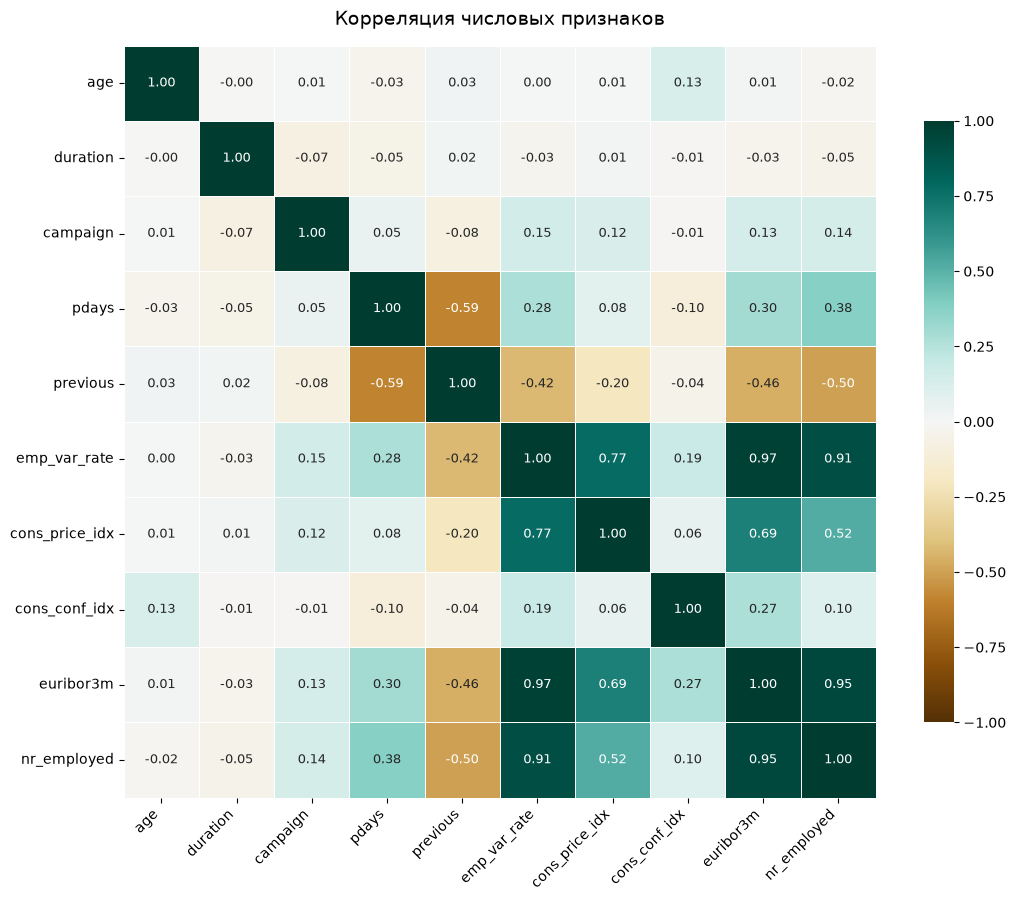

In [38]:
# Изобразим в виде Тепловой карты

plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='BrBG',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    annot_kws={'size': 9},
    cbar_kws={'shrink': 0.8}
)

plt.title('Корреляция числовых признаков', fontsize=14, pad=15)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [39]:
upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

top_corr = (
    upper.stack()
    .sort_values(key=abs, ascending=False)
    .head(10)
)

top_corr

emp_var_rate    euribor3m         0.972232
euribor3m       nr_employed       0.945275
emp_var_rate    nr_employed       0.907147
                cons_price_idx    0.774654
cons_price_idx  euribor3m         0.687515
pdays           previous         -0.587765
cons_price_idx  nr_employed       0.521542
previous        nr_employed      -0.503136
                euribor3m        -0.455685
                emp_var_rate     -0.422307
dtype: float64

### 5.6. Выводы

- Признаки `campaign`, `previous` и `duration` имеют выраженную правостороннюю асимметрию. По правилу IQR обнаружены потенциальные выбросы в `age` (1,14%), `duration` (7,14%) и `campaign` (5,73%). Пока оставим их без изменений.
- В 96,29% наблюдений `pdays = 999`, что обозначает отсутствие соответствующего предыдущего контакта. Этот признак потребует отдельной обработки.
- Доля положительных откликов заметно различается между возрастными группами. Наименьшая доля положительных откликов наблюдается среди клиентов 45–54 лет (8,32%), наибольшая — среди клиентов 65+ (46,93%). Зависимость может быть нелинейной.
- С увеличением количества контактов в текущей кампании доля положительных откликов в целом снижается. Однако это не означает, что дополнительные звонки сами по себе уменьшают вероятность согласия.
- Между экономическими показателями обнаружены сильные корреляции, особенно между `emp_var_rate`, `euribor3m` и `nr_employed`. При моделировании стоит проверить, влияет ли исключение части коррелирующих признаков на качество.
- `duration` исключим из обучения, поскольку продолжительность разговора неизвестна до его завершения.

## 6. Анализ категориальных признаков

Изучим распределения категориальных признаков и их связь с результатами маркетинговой кампании.

Сравним доли положительных откликов между категориями и выделим признаки, которые могут быть полезны для классификации.

### 6.1. Распределения категориальных признаков

Рассмотрим частоты категорий, определим наиболее распространённые и редкие значения.

In [40]:
cat_cols = df.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

cat_cols

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'poutcome']

In [41]:
df[cat_cols].nunique().sort_values(ascending=False)

job            12
month          10
education       8
day_of_week     5
marital         4
default         3
housing         3
loan            3
poutcome        3
contact         2
dtype: int64

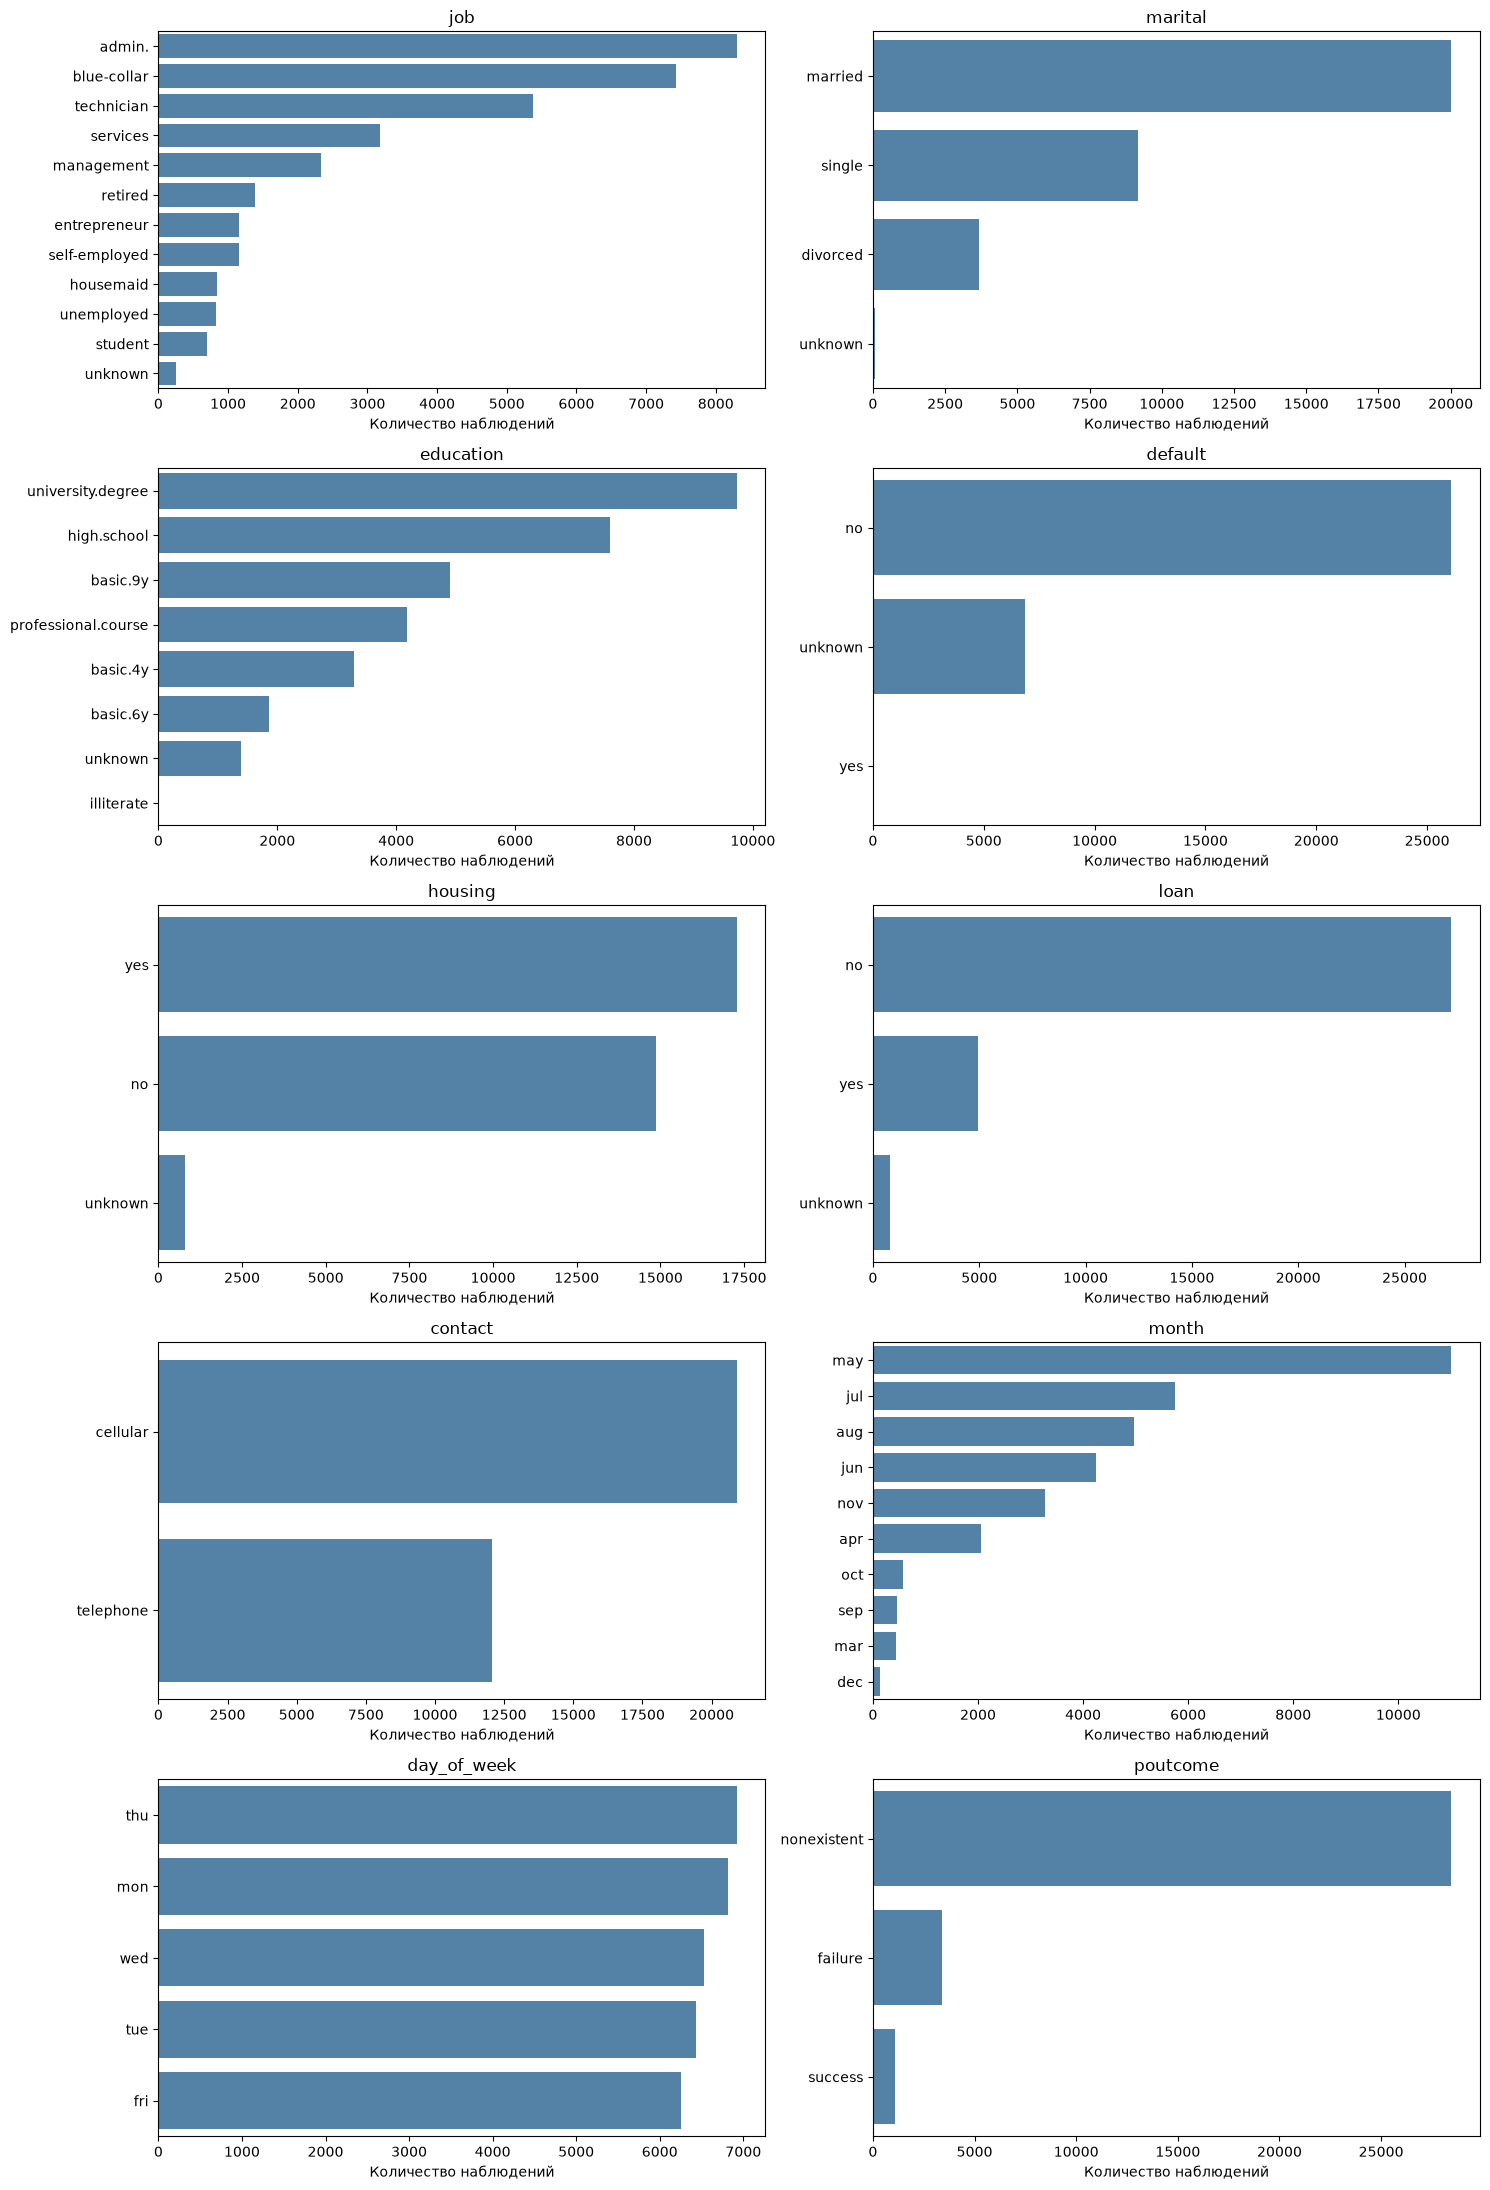

In [42]:
fig, axes = plt.subplots(5, 2, figsize=(15, 22))

for ax, col in zip(axes.flat, cat_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(col)
    ax.set_xlabel('Количество наблюдений')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [43]:
for col in cat_cols:
    shares = df[col].value_counts(normalize=True) * 100

    rare = shares[shares < 1]

    if not rare.empty:
        print(f'\n{col}:')
        print(rare.round(2))


job:
job
unknown    0.78
Name: proportion, dtype: float64

marital:
marital
unknown    0.21
Name: proportion, dtype: float64

education:
education
illiterate    0.04
Name: proportion, dtype: float64

default:
default
yes    0.01
Name: proportion, dtype: float64

month:
month
dec    0.43
Name: proportion, dtype: float64


### 6.2. Связь категориальных признаков с целевой переменной

Рассчитаем долю положительных откликов для каждой категории и сравним результаты между группами.

При анализе будем учитывать количество наблюдений, поскольку доли в малочисленных категориях могут быть нестабильными.

In [44]:
job_response = (
    df.groupby('job')['y']
    .agg(['count', 'mean'])
    .sort_values('mean', ascending=False)
)

job_response['response_rate'] = job_response['mean'] * 100

job_response[['count', 'response_rate']].round(2)

,count,response_rate
job,,
student,704,32.39
retired,1386,25.11
unemployed,829,13.87
admin.,8298,12.80
unknown,257,11.67
management,2339,10.99
technician,5375,10.92
self-employed,1152,10.33
housemaid,848,9.67


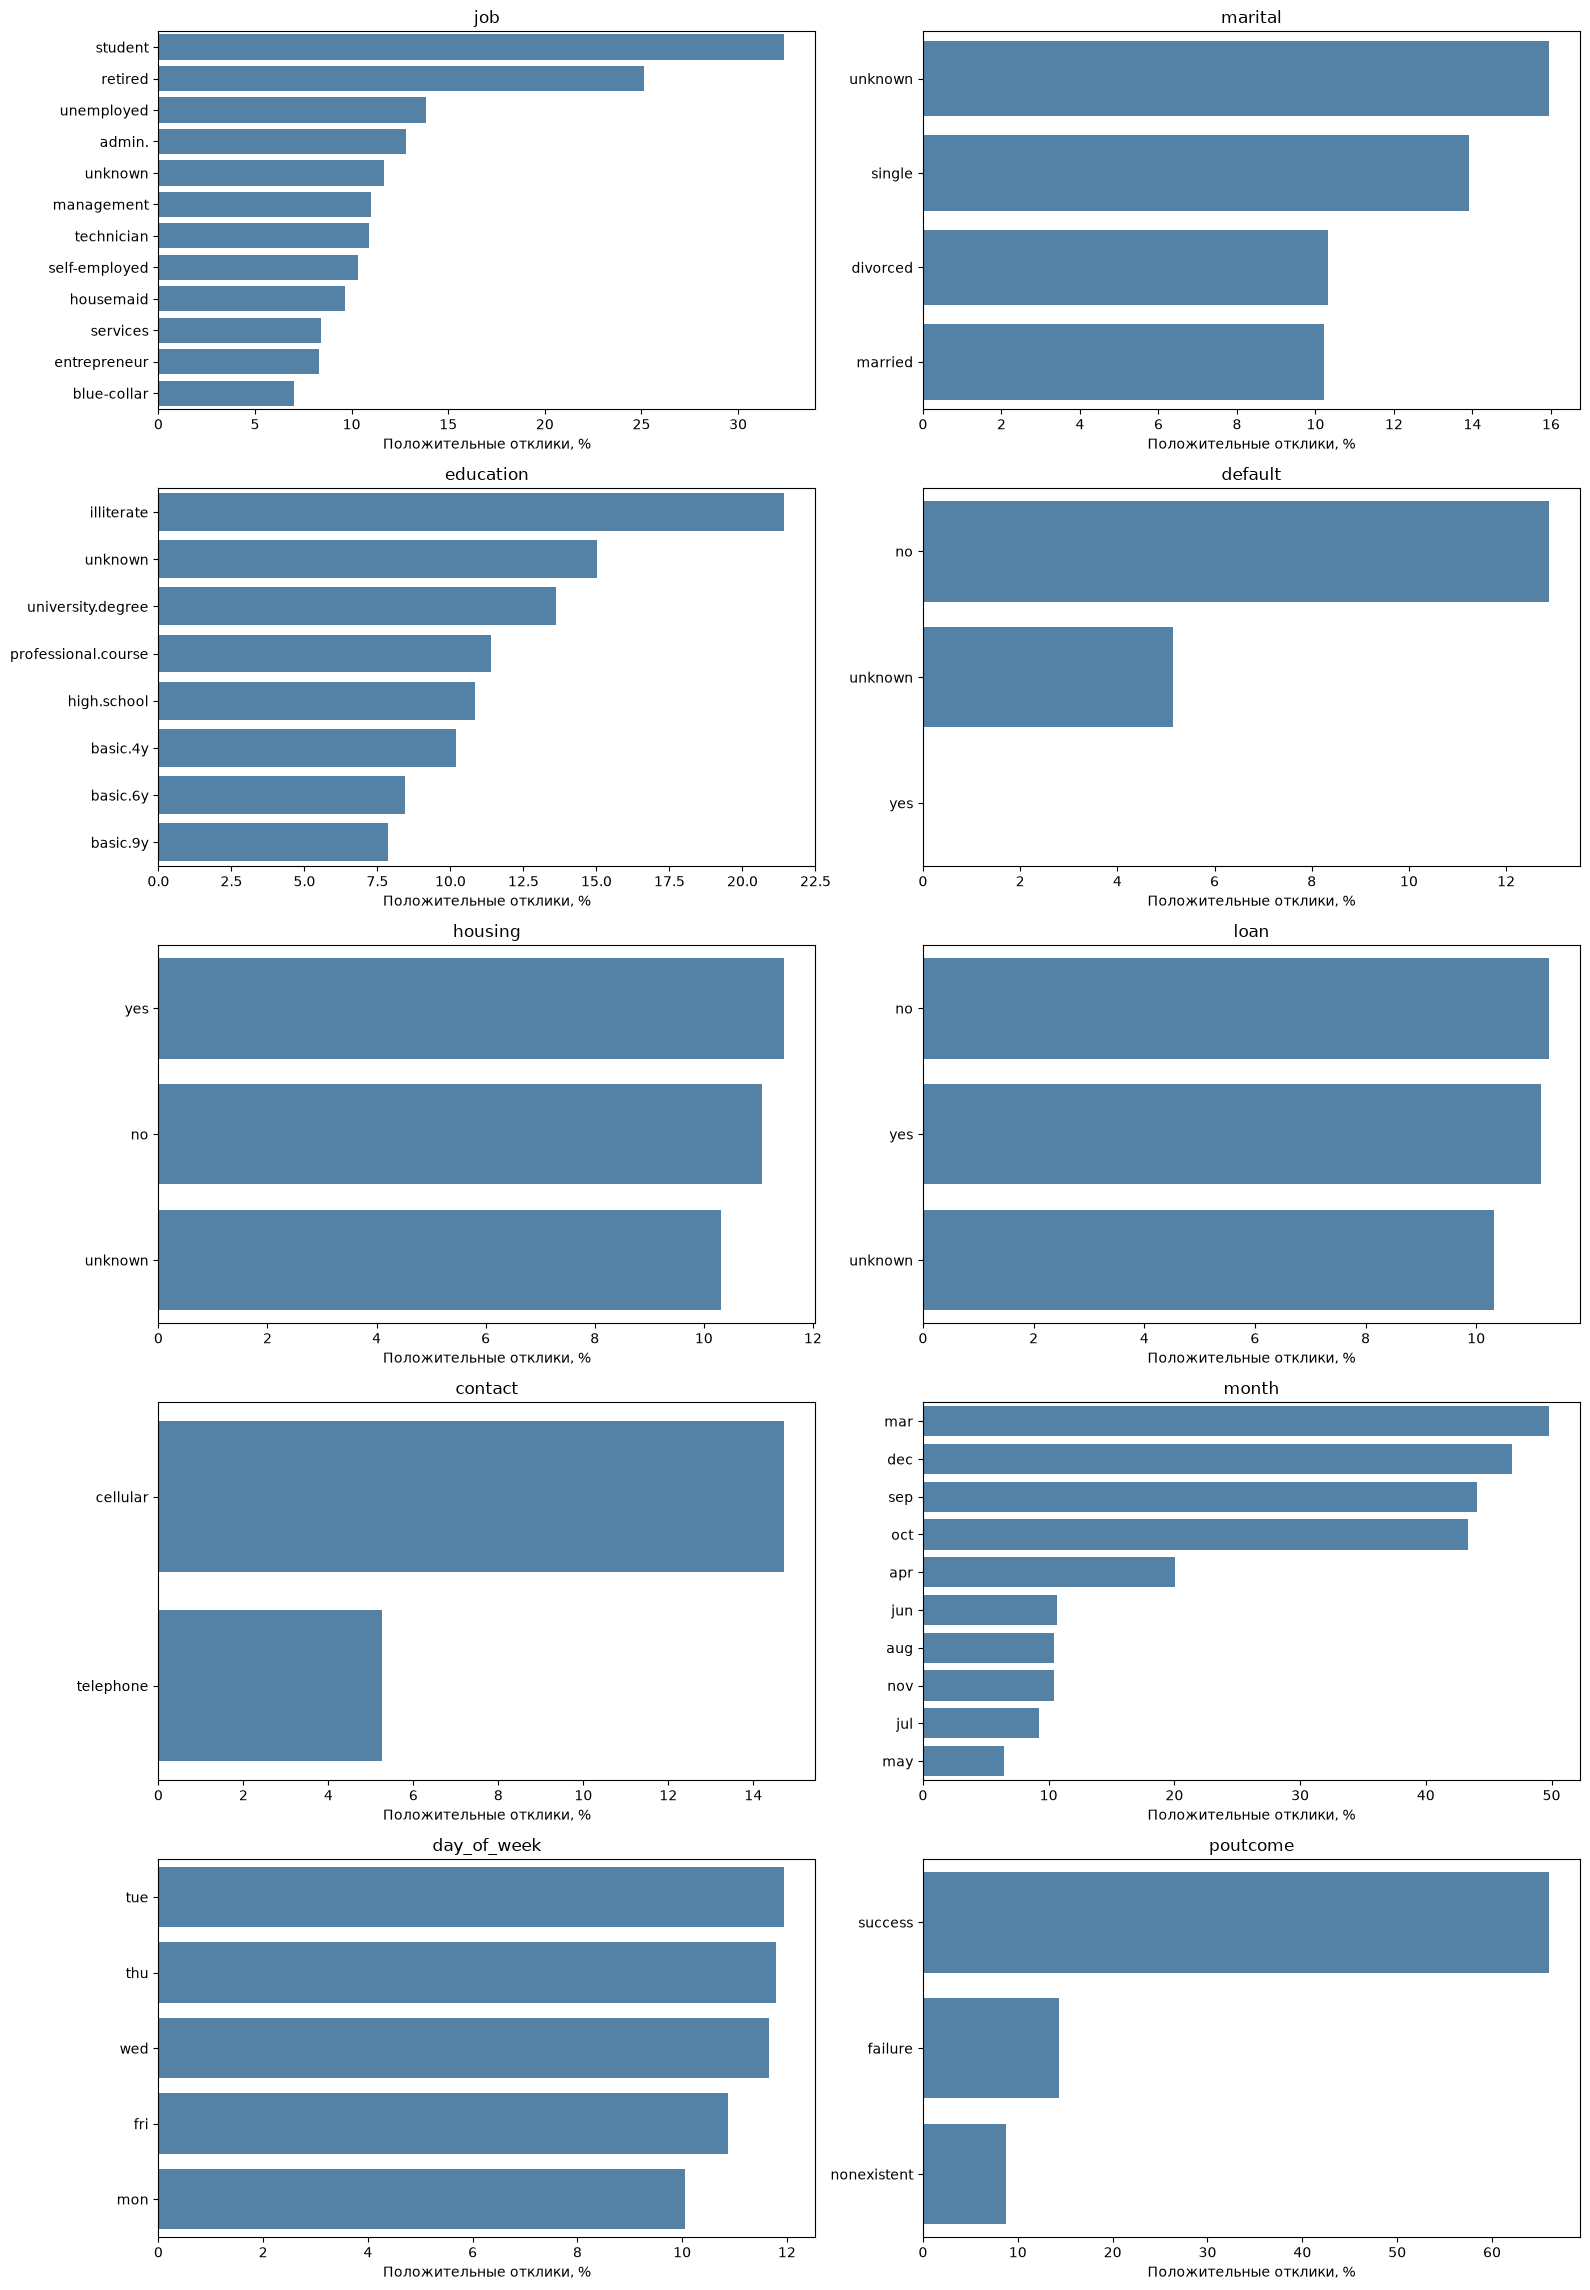

In [45]:
fig, axes = plt.subplots(5, 2, figsize=(16, 23))

for ax, col in zip(axes.flat, cat_cols):

    response = (
        df.groupby(col)['y']
        .agg(['count', 'mean'])
        .reset_index()
    )

    response['response_rate'] = response['mean'] * 100

    response = response.sort_values(
        'response_rate',
        ascending=False
    )

    sns.barplot(
        data=response,
        x='response_rate',
        y=col,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(col)
    ax.set_xlabel('Положительные отклики, %')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [46]:
response_tables = []

for col in cat_cols:

    temp = (
        df.groupby(col)['y']
        .agg(['count', 'mean'])
        .reset_index()
    )

    temp['feature'] = col
    temp['response_rate'] = temp['mean'] * 100

    temp = temp.rename(columns={col: 'category'})

    response_tables.append(
        temp[['feature', 'category', 'count', 'response_rate']]
    )

response_summary = pd.concat(
    response_tables,
    ignore_index=True
)

response_summary.sort_values(
    ['feature', 'response_rate'],
    ascending=[True, False]
).round(2)

,feature,category,count,response_rate
33,contact,cellular,20901,14.73
34,contact,telephone,12049,5.26
48,day_of_week,tue,6428,11.95
47,day_of_week,thu,6919,11.79
49,day_of_week,wed,6526,11.66
45,day_of_week,fri,6258,10.88
46,day_of_week,mon,6819,10.06
24,default,no,26080,12.88
25,default,unknown,6868,5.15
26,default,yes,2,0.00


### 6.3. Анализ результатов предыдущих кампаний

Рассмотрим признак `poutcome`, содержащий информацию о результатах предыдущих маркетинговых кампаний.

Проверим распределение категорий и сравним доли положительных откликов в зависимости от истории взаимодействия с клиентом.

In [47]:
df['poutcome'].value_counts()

poutcome
nonexistent    28442
failure         3403
success         1105
Name: count, dtype: int64

In [48]:
(df['poutcome'].value_counts(normalize=True) * 100).round(2)

poutcome
nonexistent    86.32
failure        10.33
success         3.35
Name: proportion, dtype: float64

In [49]:
pd.crosstab(
    df['poutcome'],
    df['previous'] == 0
)

previous,False,True
poutcome,,
failure,3403,0
nonexistent,0,28442
success,1105,0


In [50]:
poutcome_response = (
    df.groupby('poutcome')['y']
    .agg(['count', 'mean'])
)

poutcome_response['response_rate'] = (
    poutcome_response['mean'] * 100
)

poutcome_response[['count', 'response_rate']].round(2)

,count,response_rate
poutcome,,
failure,3403,14.31
nonexistent,28442,8.78
success,1105,65.97


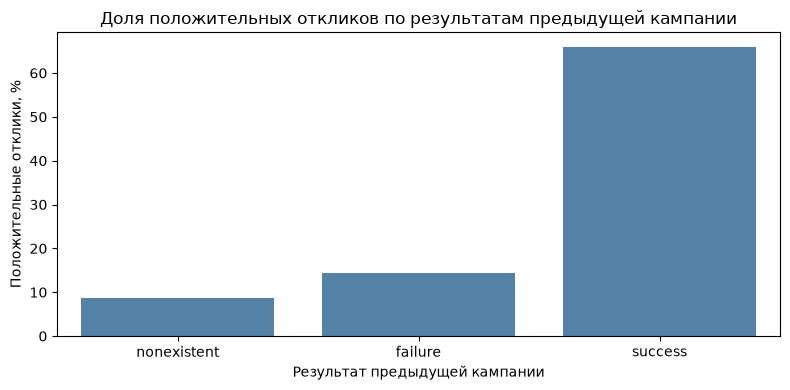

In [51]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=poutcome_response.reset_index(),
    x='poutcome',
    y='response_rate',
    order=['nonexistent', 'failure', 'success'],
    color='steelblue'
)

plt.title('Доля положительных откликов по результатам предыдущей кампании')
plt.xlabel('Результат предыдущей кампании')
plt.ylabel('Положительные отклики, %')

plt.tight_layout()
plt.show()

In [52]:
pd.crosstab(
    df['poutcome'],
    df['pdays'] == 999,
    normalize='index'
).round(3)

pdays,False,True
poutcome,,
failure,0.034,0.966
nonexistent,0.000,1.000
success,1.000,0.000


### 6.4. Выводы

- Категориальные признаки распределены неравномерно. Некоторые категории встречаются очень редко, например `default = yes` (2 наблюдения) и `education = illiterate` (14 наблюдений). Делать выводы по таким небольшим группам сложно.
- Доля положительных откликов заметно различается в зависимости от профессии. Самые высокие значения наблюдаются среди студентов (32,39%) и пенсионеров (25,11%), самые низкие — среди рабочих (`blue-collar`, 7,02%).
- При контакте по мобильному телефону положительный отклик встречается чаще (14,73%), чем при обычном телефонном контакте (5,26%). Однако эта разница может быть связана и с другими характеристиками клиентов.
- Доля положительных откликов сильно различается между месяцами: от 6,45% в мае до 49,78% в марте. Это может быть связано не только со временем года, но и с условиями проведения кампаний.
- Наиболее заметная связь с целевой переменной обнаружена у `poutcome`: среди клиентов с успешной предыдущей кампанией доля положительных откликов составляет 65,97%, при неуспешной — 14,31%, а при отсутствии предыдущих контактов — 8,78%.
- Признаки `poutcome`, `previous` и `pdays` связаны между собой, но содержат разную информацию. Пока оставим все три признака.

При предобработке потребуется закодировать категориальные переменные и определить, как обрабатывать редкие категории и значения `unknown`.

## 7. Итоговые выводы EDA

### 7.1. Основные результаты

В ходе исследования выявлены следующие особенности данных:

- Целевая переменная имеет выраженный дисбаланс классов: только 11,27% наблюдений относятся к положительному классу.
- Числовые признаки различаются по характеру распределений. Для `campaign`, `previous` и `duration` характерна выраженная правосторонняя асимметрия.
- Доля положительных откликов связана с возрастом нелинейно: более высокие значения наблюдаются среди молодых и пожилых клиентов.
- Среди категориальных признаков заметные различия в долях откликов обнаружены для `job`, `contact`, `month` и `poutcome`. Особенно выделяется результат предыдущей кампании.
- Между экономическими показателями наблюдаются сильные корреляции, что может затруднять интерпретацию коэффициентов линейных моделей.

Обнаруженные зависимости не обязательно являются причинными и могут быть связаны с другими характеристиками клиентов или условиями проведения кампаний.

### 7.2. Рекомендации для предобработки

При подготовке данных к моделированию необходимо:

1. Исключить `duration`, поскольку продолжительность разговора неизвестна до его завершения.
2. Определить способ обработки `pdays = 999` и неизвестных категорий `unknown`.
3. Проверить необходимость обработки редких категорий и потенциальных выбросов.
4. Закодировать категориальные признаки и масштабировать числовые.
5. Учесть дисбаланс классов при обучении и оценке моделей.
6. Проверить влияние сильно коррелирующих признаков на качество классификации.
7. Сохранить отложенную тестовую выборку для итоговой оценки качества моделей. Подбор преобразований и гиперпараметров выполнять только на Train с использованием кросс-валидации.

В следующем этапе будут подготовлены признаки и построены пайплайны предобработки для Logistic Regression и SVM.